# Learning a Feature Fast With Some Wrong Inputs

> **Overview.** The fast-learning LTUs of 04a with 10 wrong inputs each: do wrong inputs slow them down, and do seeded
> step-sizes or zero-crossing pruning help?

The step after `04a_fast_feature_learning.ipynb`, where LTUs that read exactly the right inputs learned fast with a high
initial step-size on their input weights. LTUs found by search will also read wrong inputs, and a high step-size makes
the weights on those wander, which may add noise and slow the LTUs down. Does it, and do two fixes help: starting each
input weight's step-size in proportion to the linear learner's weight on that input squared (*seeded step-sizes*), and
cutting an input connection as soon as its weight changes sign (*zero-crossing pruning*)?

**Problem.** As in `04a_fast_feature_learning.ipynb`: $N = 1000$ standard normal inputs, and the target is
$\frac{1}{\sqrt{8}} \sum_{k=1}^{8} \mathrm{sign}(w_k \cdot x_k)$ plus $N(0, 0.1^2)$ noise, where target LTU $k$ reads
$x_k$, the $k$-th block of 10 inputs, with random $\pm 1$ weights $w_k$. The best possible RMSE is 0.1 (dotted line),
and the best linear learner's about 0.61 (dashed line). Each seed has its own target weights.

**Learner.** As in `04a_fast_feature_learning.ipynb`: the linear learner, a bias, and 32 hidden LTUs (sigmoid derivative
backward) with fixed shadow output weights, +1 and -1 alternately, standardized online; network Autostep
(`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$). The linear learner learns alone for
the first 100k steps; then the LTUs are added and everything learns for 500k more steps. Each pair of LTUs reads one
target LTU's 10 inputs and a bias, plus 10 *wrong inputs* drawn for each LTU, either from the 920 distractors (inputs no
target LTU reads) or from the other target LTUs' inputs. When added, each LTU's input weights are LeCun uniform
magnitudes over its 20 inputs with the signs of the linear learner's weights times the LTU's shadow weight, and their
step-sizes start at $3 \times 10^{-2}$: the best in `04a_fast_feature_learning.ipynb`.

**Fixes**, alone and together:
- *Seeded step-sizes*: each input weight's step-size starts at $3 \times 10^{-2}$ times the square of the linear
  learner's weight on that input, relative to the largest among the LTU's inputs.
- *Zero-crossing pruning*: an input connection is cut, for good, the first time its weight changes sign.

**Runs.** 5 seeds per configuration; the same seed gives every run the same samples and target weights. *Right inputs
only* (reference): the LTUs read only their target LTU's 10 inputs, as in `04a_fast_feature_learning.ipynb`. *Linear
learner* (baseline): no LTUs. Curves are the mean over seeds of the RMSE averaged over windows of 1k steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # each target LTU reads its own block of N_SOURCES inputs, from the first
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs, each pair reading one target LTU's inputs
N_WRONG = 10                         # wrong inputs read by each LTU
FAST_STEP_SIZE = 3e-2                # initial step-size of the LTUs' input weights

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 500_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot


NONE, DISTRACTORS, OTHER_TARGETS = 0, 1, 2   # an LTU's wrong inputs: none, distractors, or other target LTUs' inputs


def init_net(key, units, slots, wrong):
    # `units` hidden units in `slots` slots, the rest left empty, each pair reading the inputs of one of the N_TARGETS
    # target LTUs in turn, N_WRONG wrong inputs of the kind `wrong` drawn for each unit without replacement, and the
    # bias; their shadow weights +1 and -1 alternately, their input weights LeCun uniform over their fan-in; every
    # other weight at 0.
    w_key, wrong_key = jax.random.split(key)
    block = jnp.arange(N_INPUTS) // N_SOURCES    # the target LTU that reads each input (N_TARGETS and up: none)
    right = block == (jnp.arange(slots) // 2 % N_TARGETS)[:, None]
    candidates = jnp.where(wrong == DISTRACTORS, block >= N_TARGETS, (block < N_TARGETS) & ~right)
    scores = jnp.where(candidates, jax.random.gumbel(wrong_key, (slots, N_INPUTS)), -jnp.inf)
    extra = (jnp.argsort(jnp.argsort(-scores)) < N_WRONG) & (wrong != NONE)
    reads = jnp.append(right | extra, jnp.ones((slots, 1), bool), axis=1)
    fan_in = reads[:, :N_INPUTS].sum(1, keepdims=True)
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(w_key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow)


class Variant(NamedTuple):
    seeded: bool = False        # seeded step-sizes
    pruned: bool = False        # zero-crossing pruning


def add_units(net, variant):
    # The hidden units' input weights at addition: their LeCun uniform magnitudes with the signs of the linear learner's
    # weights on those inputs times the unit's shadow weight. Their step-sizes start at FAST_STEP_SIZE, or if seeded at
    # FAST_STEP_SIZE times the square of the linear learner's weight on each input relative to the largest among the
    # unit's inputs.
    linear = jnp.append(net.w['output'][0, :N_INPUTS], 0.0) * net.reads.at[:, -1].set(False)
    hidden = jnp.abs(net.w['hidden']) * jnp.sign(net.shadow[:, None] * linear)
    relative = linear ** 2 / jnp.max(linear ** 2, axis=1, keepdims=True)
    step = FAST_STEP_SIZE * jnp.where(variant.seeded, relative, 1.0)
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(step), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def prune_crossed(net, before):
    # Cuts every input connection of a hidden unit whose weight has changed sign since `before`.
    crossed = (jnp.sign(net.w['hidden']) != jnp.sign(before)) & net.reads.at[:, -1].set(False)
    reads = net.reads & ~crossed
    return net._replace(w={**net.w, 'hidden': net.w['hidden'] * reads}, reads=reads)


def learn(net, x, y):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude. Returns the new network and
    # the squared error on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at
    # each hidden unit.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(units))
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss

## Training

In [4]:
def train(net, key, variant, add_step, num_steps):
    # num_steps online network-Autostep steps on targets from this seed's target LTUs, the hidden units added at
    # add_step as the variant says. Returns each window's mean squared error.
    target_key, key = jax.random.split(key)
    target_w = jax.random.rademacher(target_key, (N_TARGETS, N_SOURCES), dtype=float)

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        blocks = x[:target_w.size].reshape(target_w.shape)
        y = (jnp.sum(jnp.where(jnp.sum(target_w * blocks, 1) > 0, 1.0, -1.0)) / np.sqrt(N_TARGETS)
             + NOISE_STD * jax.random.normal(noise_key, (1,)))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        learned, mse = learn(net, x, y)
        return jax.tree.map(lambda a, b: jnp.where(variant.pruned, a, b),
                            prune_crossed(learned, net.w['hidden']), learned), mse

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        return net, mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = add_units(net, variant)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(units, configs):
    # Each (wrong, variant) of configs: `units` hidden LTUs (none: the linear learner alone) reading wrong inputs of
    # the kind `wrong`, started as the variant says, each on N_SEEDS seeds, vmapped together. Seed s gives every run the
    # same samples and target weights. Returns {config: the RMSE of each window from step 1, shaped (seed, window)}.
    seed = jnp.tile(jnp.arange(N_SEEDS), len(configs))
    wrong = jnp.repeat(jnp.array([c[0] for c in configs]), N_SEEDS)
    variants = Variant(*(jnp.repeat(jnp.array(v), N_SEEDS) for v in zip(*[c[1] for c in configs])))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(lambda k, r: init_net(k, units, max(units, 1), r))(keys(0), wrong)
    train_all = jax.jit(jax.vmap(lambda n, k, v: train(n, k, v, LINEAR_STEPS, LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), variants)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [5]:
FIXES = {'no fix': Variant(), 'seeded step-sizes': Variant(seeded=True),
         'zero-crossing pruning': Variant(pruned=True), 'both': Variant(seeded=True, pruned=True)}
WRONG = {'10 distractors': DISTRACTORS, "10 of the other target LTUs' inputs": OTHER_TARGETS}
started = perf_counter()
linear = run(0, [(NONE, Variant())])[(NONE, Variant())]
rmse = run(N_LTUS, [(NONE, Variant())] + [(wrong, fix) for wrong in WRONG.values() for fix in FIXES.values()])
print(f'{(len(rmse) + 1) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

50 runs in 59s


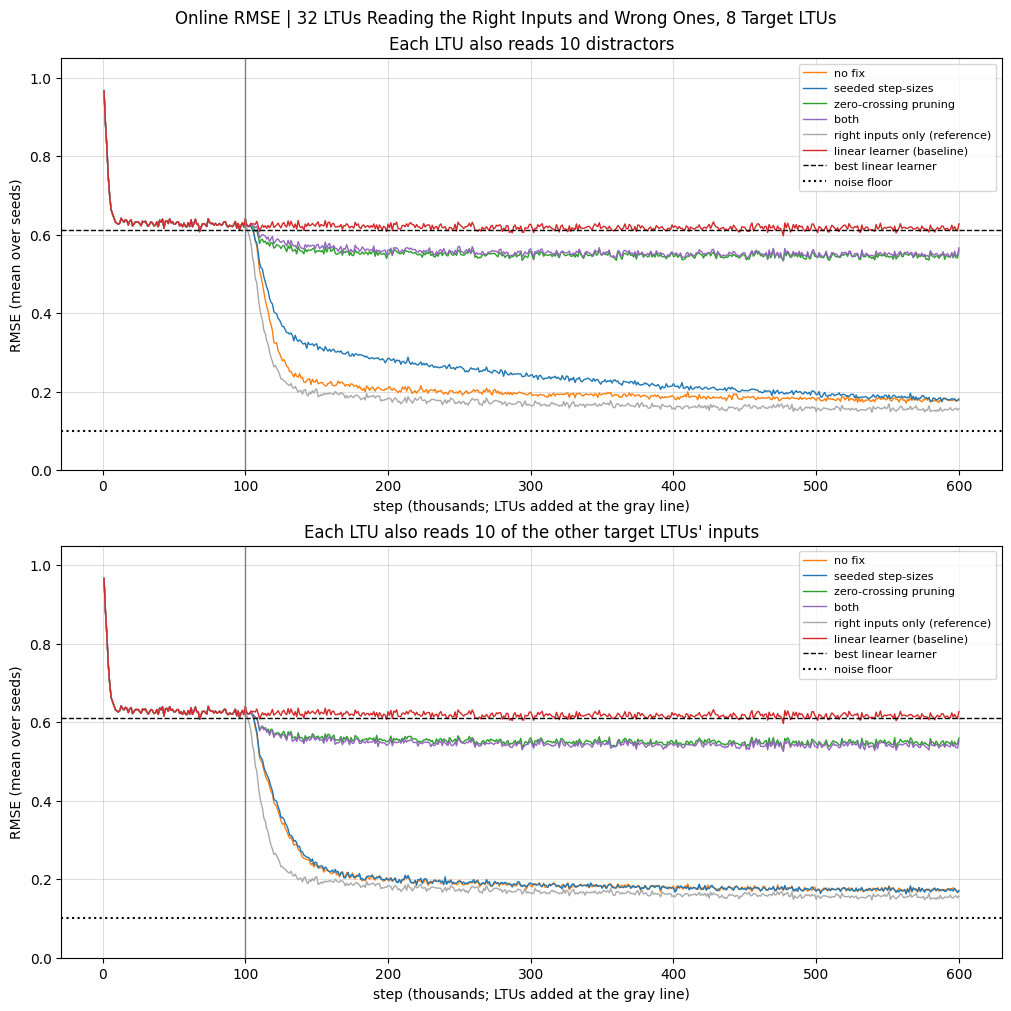

In [6]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
curve = lambda ax, rmse, **style: ax.plot(STEPS / 1000, rmse.mean(0), lw=1, **style)

fig, axes = plt.subplots(len(WRONG), 1, figsize=(10, 5 * len(WRONG)), layout='constrained')
for ax, (title, wrong) in zip(axes, WRONG.items()):
    for (label, fix), color in zip(FIXES.items(), ['tab:orange', 'tab:blue', 'tab:green', 'tab:purple']):
        curve(ax, rmse[(wrong, fix)], color=color, label=label)
    curve(ax, rmse[(NONE, Variant())], color='darkgray', label='right inputs only (reference)')
    curve(ax, linear, color='tab:red', label='linear learner (baseline)')
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE (mean over seeds)', ylim=(0, 1.05),
           title=f'Each LTU also reads {title}')
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
fig.suptitle(f'Online RMSE | {N_LTUS} LTUs Reading the Right Inputs and Wrong Ones, {N_TARGETS} Target LTUs')
plt.show()

## Results

5 seeds per configuration. The notebook takes about 1 minute.

- **Wrong inputs slow the LTUs only a little**: with 10 distractors or 10 of the other target LTUs' inputs they reach
  RMSE 0.2 in a median 57k and 69k steps after being added (36k with the right inputs only) and end at 0.18 and 0.17
  (0.155).
- **Seeded step-sizes don't help.**
- **Zero-crossing pruning breaks learning** (0.55): at step-size $3 \times 10^{-2}$ noise flips the right weights too.
  Checked separately (distractors, 2 seeds), it cuts a third of the right inputs within 1k steps and half within 10k,
  while cutting 96% of the wrong ones by 100k.